# Previsão de falhas em máquinas industriais

**Pergunta:** a partir das leituras de sensores de uma fresadora, dá para prever se a próxima operação vai falhar, a tempo de parar a máquina e fazer manutenção?

Dataset: [AI4I 2020 Predictive Maintenance](https://archive.ics.uci.edu/dataset/601) (S. Matzka, UCI, licença CC BY 4.0), com 10 mil leituras.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from falhas import dados, modelo

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
bruto = pd.read_csv(dados.ARQUIVO_PADRAO)
df = dados.carregar()
df.head()

,tipo,temp_ar_k,temp_processo_k,rotacao_rpm,torque_nm,desgaste_min,delta_temp_k,potencia_w,esforco_ferramenta,falha
0,M,298.1,308.6,1551,42.8,0,10.5,6951.590560,0.0,0
1,L,298.2,308.7,1408,46.3,3,10.5,6826.722724,138.9,0
2,L,298.1,308.5,1498,49.4,5,10.4,7749.387543,247.0,0
3,L,298.2,308.6,1433,39.5,7,10.4,5927.504659,276.5,0
4,L,298.2,308.7,1408,40.0,9,10.5,5897.816608,360.0,0


## 1. Classes desbalanceadas

Só cerca de 3% das leituras terminam em falha. Por isso a acurácia engana: um modelo que sempre diz "não vai falhar" acerta 97%.

Taxa de falha: 3.39%


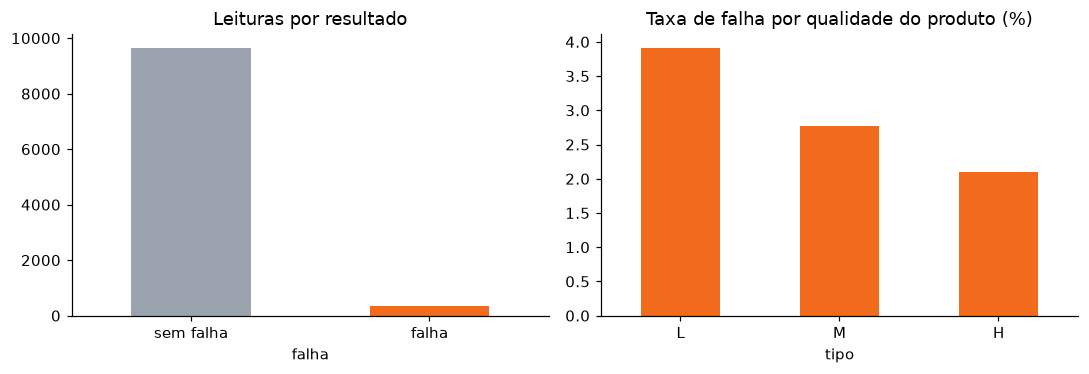

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
df['falha'].value_counts().rename({0: 'sem falha', 1: 'falha'}).plot.bar(ax=axes[0], color=['#9aa3ae', '#f26b1d'])
axes[0].set_title('Leituras por resultado'); axes[0].tick_params(axis='x', rotation=0)
(df.groupby('tipo')['falha'].mean() * 100).reindex(['L', 'M', 'H']).plot.bar(ax=axes[1], color='#f26b1d')
axes[1].set_title('Taxa de falha por qualidade do produto (%)'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
print(f"Taxa de falha: {df['falha'].mean():.2%}")

## 2. Tipos de falha (e por que eles ficam fora do modelo)

O dataset informa **qual** falha aconteceu: desgaste da ferramenta (TWF), dissipação de calor (HDF), potência (PWF), sobrecarga (OSF) e aleatória (RNF). Essas colunas só existem **depois** da falha. Usá-las como entrada seria vazamento de dados, então elas servem apenas para entender o problema.

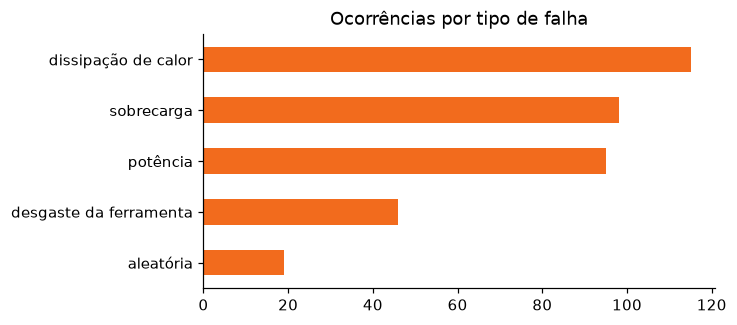

In [3]:
tipos = bruto[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum().sort_values(ascending=False)
tipos.index = ['dissipação de calor' if t == 'HDF' else 'sobrecarga' if t == 'OSF' else 'potência' if t == 'PWF'
               else 'desgaste da ferramenta' if t == 'TWF' else 'aleatória' for t in tipos.index]
tipos.plot.barh(color='#f26b1d', figsize=(6, 3), title='Ocorrências por tipo de falha').invert_yaxis()

## 3. Features baseadas na física da máquina

Além das leituras originais, foram criadas três variáveis ligadas aos mecanismos de falha:

| Feature | Fórmula | Mecanismo |
|---|---|---|
| `delta_temp_k` | T processo − T ar | calor mal dissipado quando a diferença é pequena |
| `potencia_w` | torque × rotação × 2π/60 | falha com potência muito baixa ou muito alta |
| `esforco_ferramenta` | desgaste × torque | ferramenta gasta trabalhando com força |


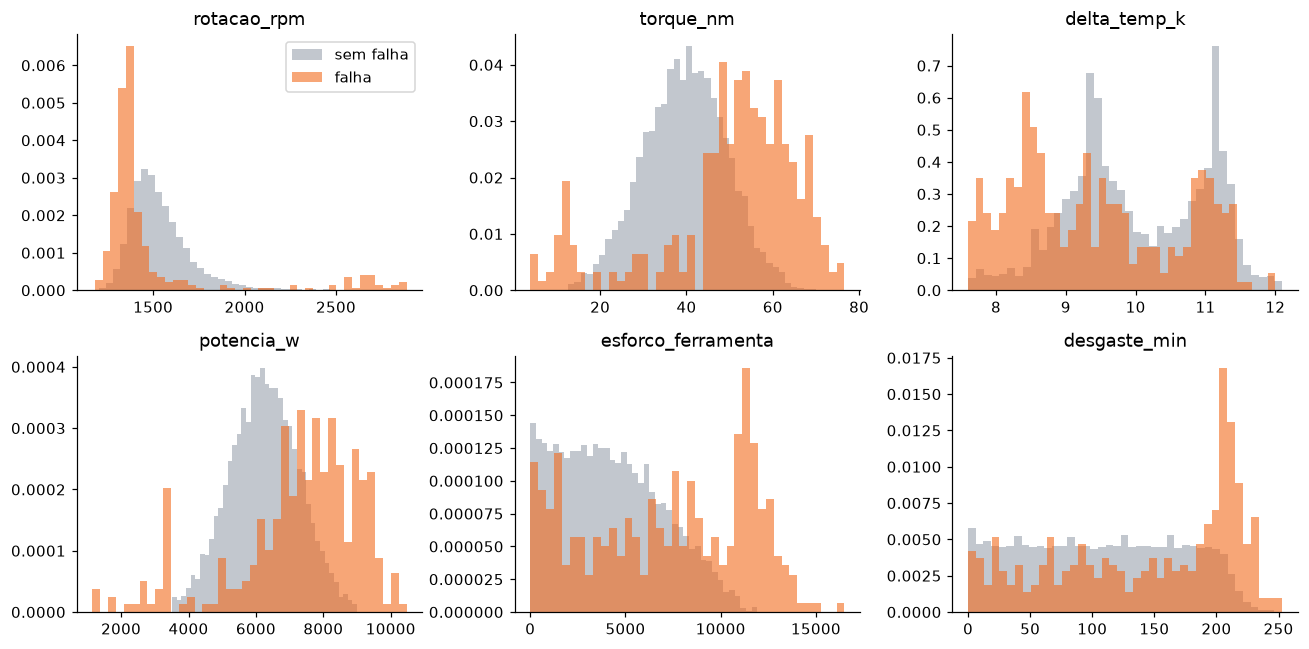

In [4]:
variaveis = ['rotacao_rpm', 'torque_nm', 'delta_temp_k', 'potencia_w', 'esforco_ferramenta', 'desgaste_min']
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, coluna in zip(axes.flat, variaveis):
    for classe, cor, nome in [(0, '#9aa3ae', 'sem falha'), (1, '#f26b1d', 'falha')]:
        ax.hist(df.loc[df['falha'] == classe, coluna], bins=40, density=True, alpha=0.6, color=cor, label=nome)
    ax.set_title(coluna)
axes[0, 0].legend()
plt.tight_layout()

As falhas se concentram nas pontas: potência muito baixa ou muito alta, esforço alto e pouca diferença de temperatura. É exatamente o que as features novas capturam.

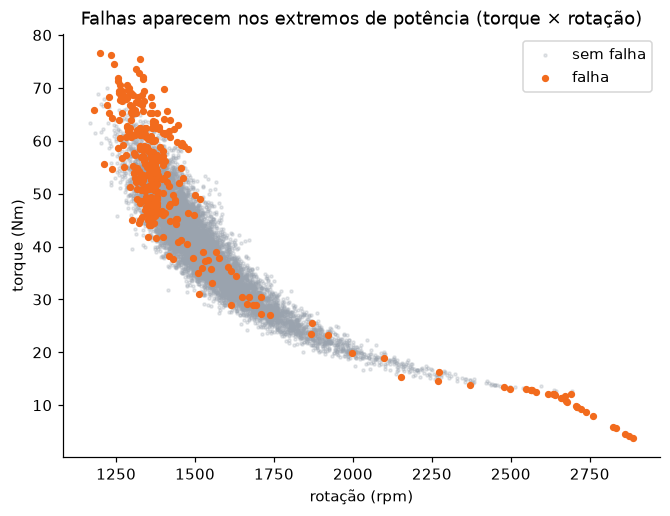

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
normais, falhas = df[df['falha'] == 0], df[df['falha'] == 1]
ax.scatter(normais['rotacao_rpm'], normais['torque_nm'], s=4, alpha=0.25, color='#9aa3ae', label='sem falha')
ax.scatter(falhas['rotacao_rpm'], falhas['torque_nm'], s=14, color='#f26b1d', label='falha')
ax.set_xlabel('rotação (rpm)'); ax.set_ylabel('torque (Nm)')
ax.set_title('Falhas aparecem nos extremos de potência (torque × rotação)')
ax.legend();

## 4. Modelagem

- Separação **80/20 estratificada**. O conjunto de teste só é usado uma vez, no final
- **3 candidatos:** regressão logística, random forest e gradient boosting, todos com peso maior para a classe rara
- Comparação pela **PR-AUC** (área sob a curva precisão-recall) em validação cruzada de 5 dobras, porque ela é a métrica adequada para classes desbalanceadas
- **Limiar de decisão** escolhido pelo **F2**: deixar passar uma falha custa mais que um alarme falso, então o recall pesa o dobro da precisão

In [6]:
resultado = modelo.treinar(df)
pd.DataFrame(resultado.comparacao).T.sort_values('pr_auc', ascending=False)

,pr_auc,roc_auc
random_forest,0.8926,0.9769
gradient_boosting,0.8842,0.9719
regressao_logistica,0.4552,0.9223


In [7]:
print(f'Modelo escolhido: {resultado.nome}')
print(f'Limiar de decisão: {resultado.limiar:.2f}')
pd.Series({k: v for k, v in resultado.teste.items() if k != 'matriz_confusao'}, name='teste').to_frame()

Modelo escolhido: random_forest
Limiar de decisão: 0.38


,teste
roc_auc,0.9798
pr_auc,0.8780
precisao,0.9062
recall,0.8529
f1,0.8788
f2,0.8631


In [8]:
cm = resultado.teste['matriz_confusao']
print(f"Das {cm['vp'] + cm['fn']} falhas do teste, o modelo antecipou {cm['vp']} "
      f"e gerou {cm['fp']} alarmes falsos em {cm['vn'] + cm['fp']} operações normais.")

Das 68 falhas do teste, o modelo antecipou 58 e gerou 6 alarmes falsos em 1932 operações normais.


## 5. Conclusões

- O modelo é **muito melhor que o acaso**: PR-AUC perto de 0,88 contra 0,034 de um palpite aleatório
- Com o limiar escolhido pelo F2, ele antecipa a grande maioria das falhas e gera poucos alarmes falsos
- As features físicas (`delta_temp_k`, `esforco_ferramenta`, `potencia_w`) estão entre as mais importantes (veja `relatorio/importancia_features.png`)
- As falhas aleatórias (RNF), por definição, não são previsíveis pelos sensores

**Próximos passos:** calibração das probabilidades, um limiar por tipo de produto e um monitoramento de *drift* com os dados de produção.